# Early-Stage Deal Sourcing: Predicting Follow-On Rounds from SEC Form D Filings

US companies that raise money under Regulation D (equity, SAFEs, convertible notes) must file a **Form D** with the SEC within 15 days of the first sale. That makes Form D a free, point-in-time record of private fundraising across the US. This notebook turns the SEC's quarterly Form D data sets into a **deal-sourcing model for a seed fund**: it reconstructs funding rounds from raw filings, isolates each young company's first observed round, links its board to VC fund filings, and predicts whether the company will file a **larger follow-on round within 18 months**, the event that separates companies that gained traction from those that stalled. The funding climate (Fed funds rate from FRED, Nasdaq from Yahoo Finance) is added as context. Models are validated walk-forward with an embargo, so no fold ever trains on outcomes that were unknown at the time. The output is a ranked **watchlist of young companies that raised recently**, measured by the metric a partner cares about: the hit rate at the top of the list.

## 0. Setup
Installs and imports. Colab already includes everything except the latest `yfinance`.

In [ ]:
!pip install -q --upgrade yfinance

import csv
import io
import re
import time
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
import plotly.express as px
import yfinance as yf
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)

# Chart style: light surface, hairline grid, thin marks, one color per entity
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
MODEL_COLORS = {"Gradient boosting": BLUE, "Logistic regression": ORANGE, "Heuristic rule": AQUA}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelcolor": INK_2, "axes.labelsize": 9.5, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "text.color": INK, "legend.frameon": False,
    "legend.fontsize": 9, "lines.linewidth": 2, "figure.dpi": 110,
})
print(f"pandas {pd.__version__} | yfinance {yf.__version__} | ready")

pandas 2.2.3 | yfinance 1.7.0 | ready


## 1. Configuration
All assumptions live here. **Set `SEC_USER_AGENT` to your name and email before running**: the SEC blocks automated requests that don't identify themselves.

In [ ]:
SEC_USER_AGENT = "Your Name your.email@example.com"   # <-- replace with your name + email (required by the SEC)

START_YEAR = 2016          # first year of Form D data to load (earlier = more history, slower download)
END_YEAR = None            # None = through the latest quarter the SEC has published
CACHE_DIR = Path("/content/formd_cache") if Path("/content").exists() else Path("formd_cache")
OUTPUT_DIR = CACHE_DIR.parent

# Entry round = the first Form D we ever see from a young venture-type company
ENTRY_MIN_SIZE = 100_000
ENTRY_MAX_SIZE = 15_000_000
MAX_COMPANY_AGE_YEARS = 5
BURN_IN_DAYS = 365         # companies first seen in year one of the data may have raised earlier; skip them

# Label = a larger follow-on round filed within ~18 months
FOLLOW_ON_MIN_GAP_DAYS = 90
FOLLOW_ON_WINDOW_DAYS = 540
FOLLOW_ON_STEP_UP = 1.5    # the next round must be at least 1.5x the entry round...
FOLLOW_ON_MIN_SIZE = 1_000_000  # ...and at least $1M, so a $100k -> $150k top-up doesn't count as success

# Form D industry groups mapped to the sectors a generalist seed fund covers
SECTOR_MAP = {
    "other technology": "Software & IT",
    "computers": "Software & IT",
    "telecommunications": "Telecom",
    "biotechnology": "Biotech & Pharma",
    "pharmaceuticals": "Biotech & Pharma",
    "other health care": "Health Care",
    "health insurance": "Health Care",
    "business services": "Business Services",
    "energy conservation": "Climate & Energy",
    "environmental services": "Climate & Energy",
    "manufacturing": "Hardware & Manufacturing",
    "retailing": "Consumer",
}
VC_ENTITY_TYPES = {"corporation", "limited liability company"}
VC_FUND_TYPES = {"venture capital fund", "private equity fund"}  # fund filings whose managers count as investors
MAX_COMPANIES_PER_NAME = 60  # a name on more venture filings than this is too common to match reliably
TECH_HUBS = ["CA", "NY", "MA", "WA", "TX"]   # states kept as their own location category in the features
HEURISTIC_HUBS = ["CA", "NY", "MA"]          # the checklist baseline only rewards the three largest VC hubs

TOP_K = 100                # size of the yearly shortlist a partner would actually review
MIN_TRAIN_ROWS = 1_000
RANDOM_STATE = 42

## 2. Download the SEC Form D data sets
The SEC publishes Form D filings as quarterly zip files of six tab-separated tables linked by `ACCESSIONNUMBER`. We keep four of them: the submission header, the issuer, the offering terms, and the related persons (the names and roles of officers, directors and promoters), plus a count of sales-commission recipients (brokers). Each zip is downloaded once and cached.

In [ ]:
FORMD_INDEX_URL = "https://www.sec.gov/data-research/sec-markets-data/form-d-data-sets"
FORMD_URL_BASES = (
    "https://www.sec.gov/files/structureddata/data/form-d-data-sets",
    "https://www.sec.gov/files/datastandardsinnovation/data/form-d-data-sets",
)
FORMD_COLUMNS = {
    "FORMDSUBMISSION": ["ACCESSIONNUMBER", "FILING_DATE", "SUBMISSIONTYPE"],
    "ISSUERS": ["ACCESSIONNUMBER", "IS_PRIMARYISSUER_FLAG", "ISSUER_SEQ_KEY", "CIK", "ENTITYNAME", "CITY",
                "STATEORCOUNTRY", "JURISDICTIONOFINC", "ENTITYTYPE", "YEAROFINC_TIMESPAN_CHOICE",
                "YEAROFINC_VALUE_ENTERED"],
    "OFFERING": ["ACCESSIONNUMBER", "INDUSTRYGROUPTYPE", "INVESTMENTFUNDTYPE", "REVENUERANGE", "FEDERALEXEMPTIONS_ITEMS_LIST",
                 "ISAMENDMENT", "PREVIOUSACCESSIONNUMBER", "SALE_DATE", "MORETHANONEYEAR", "ISEQUITYTYPE",
                 "ISDEBTTYPE", "ISOPTIONTOACQUIRETYPE", "ISSECURITYTOBEACQUIREDTYPE",
                 "ISPOOLEDINVESTMENTFUNDTYPE", "ISOTHERTYPE", "ISBUSINESSCOMBINATIONTRANS",
                 "MINIMUMINVESTMENTACCEPTED", "TOTALOFFERINGAMOUNT", "TOTALAMOUNTSOLD",
                 "HASNONACCREDITEDINVESTORS", "TOTALNUMBERALREADYINVESTED", "SALESCOMM_DOLLARAMOUNT",
                 "FINDERSFEE_DOLLARAMOUNT"],
    "RELATEDPERSONS": ["ACCESSIONNUMBER", "FIRSTNAME", "LASTNAME", "RELATIONSHIP_1", "RELATIONSHIP_2", "RELATIONSHIP_3"],
    "RECIPIENTS": ["ACCESSIONNUMBER"],
}

if "example.com" in SEC_USER_AGENT:
    print("WARNING: set SEC_USER_AGENT in the configuration cell to your own name and email.")

sec = requests.Session()
sec.headers.update({"User-Agent": SEC_USER_AGENT, "Accept-Encoding": "gzip, deflate"})


def discover_formd_zip_urls():
    # The SEC has moved these files between folders, so read the live index page first.
    try:
        resp = sec.get(FORMD_INDEX_URL, timeout=30)
        resp.raise_for_status()
    except requests.RequestException as exc:
        print(f"SEC index page unavailable ({type(exc).__name__}); falling back to known URL patterns.")
        return {}
    found = {}
    for href in re.findall(r'href="([^"]*form-d-data-sets/[^"]*\.zip)"', resp.text, flags=re.IGNORECASE):
        match = re.search(r"(\d{4})q([1-4])_d", href, flags=re.IGNORECASE)
        if match:
            url = href if href.startswith("http") else f"https://www.sec.gov{href}"
            found[(int(match.group(1)), int(match.group(2)))] = url
    print(f"SEC index lists {len(found)} quarterly files.")
    return found


def download_quarter(year, quarter, known_urls):
    target = CACHE_DIR / f"{year}q{quarter}_d.zip"
    if target.exists() and zipfile.is_zipfile(target):
        return target
    candidates = [known_urls.get((year, quarter))]
    candidates += [f"{base}/{year}q{quarter}_d{suffix}.zip" for base in FORMD_URL_BASES for suffix in ("", "_0")]
    for url in dict.fromkeys(u for u in candidates if u):
        try:
            resp = sec.get(url, timeout=120)
        except requests.RequestException:
            continue
        finally:
            time.sleep(0.15)  # stay well under the SEC's 10 requests/second fair-access limit
        if resp.status_code == 403:
            download_quarter.saw_403 = True
        if resp.status_code == 200 and resp.content[:2] == b"PK":
            target.write_bytes(resp.content)
            return target
    return None


download_quarter.saw_403 = False


PARSE_LOG = []  # (quarter, table, lines in file, rows parsed, fragments dropped) so no data is lost silently
ACCESSION_PATTERN = r"\d{10}-?\d{2}-?\d{6}"


def read_formd_table(zip_path, table, columns, label=""):
    wanted = set(columns)
    with zipfile.ZipFile(zip_path) as zf:
        member = next((n for n in zf.namelist() if Path(n).name.upper() == f"{table}.TSV"), None)
        if member is None:
            return pd.DataFrame(columns=columns)
        raw_bytes = zf.read(member)
    data_lines = sum(1 for line in raw_bytes.splitlines()[1:] if line.strip())
    df = pd.read_csv(io.BytesIO(raw_bytes), sep="\t", dtype=str, quoting=csv.QUOTE_NONE, encoding="utf-8-sig",
                     encoding_errors="replace", on_bad_lines="skip",
                     usecols=lambda c: c.strip().upper() in wanted)
    df.columns = [c.strip().upper() for c in df.columns]
    # A line break inside a free-text field splits one record into fragments; a fragment has no valid accession number
    valid = df["ACCESSIONNUMBER"].astype("string").str.strip().str.fullmatch(ACCESSION_PATTERN).fillna(False).astype(bool)
    if valid.mean() < 0.5:  # unexpected ID format: keep everything rather than drop real data
        valid[:] = True
    PARSE_LOG.append((label, table, data_lines, len(df), int((~valid).sum())))
    return df.loc[valid.to_numpy()].reindex(columns=columns)


def normalize_name(series):
    ascii_text = series.fillna("").str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii")
    return ascii_text.str.lower().str.replace(r"[^a-z ]", "", regex=True).str.strip()


def slim_related_persons(df):
    # One row per person per filing: a normalized "first last" key plus role flags
    roles = (df["RELATIONSHIP_1"].fillna("") + " " + df["RELATIONSHIP_2"].fillna("") + " "
             + df["RELATIONSHIP_3"].fillna("")).str.lower()
    first = normalize_name(df["FIRSTNAME"]).str.split().str[0].fillna("")
    last = normalize_name(df["LASTNAME"]).str.replace(" ", "", regex=False)
    person = (first + " " + last).where(first.ne("") & last.ne(""))
    return pd.DataFrame({
        "ACCESSIONNUMBER": df["ACCESSIONNUMBER"],
        "person": person,
        "is_director": roles.str.contains("director", regex=False),
        "is_officer": roles.str.contains("officer", regex=False),
        "is_promoter": roles.str.contains("promoter", regex=False),
    })


def count_recipients(df):
    return df.groupby("ACCESSIONNUMBER").size().rename("n_recipients").reset_index()


CACHE_DIR.mkdir(parents=True, exist_ok=True)
known_urls = discover_formd_zip_urls()
today = pd.Timestamp.today()
last_year = END_YEAR or (max(known_urls)[0] if known_urls else today.year)
quarters = [(y, q) for y in range(START_YEAR, last_year + 1) for q in range(1, 5)
            if pd.Timestamp(year=y, month=3 * q - 2, day=1) <= today]

frames = {table: [] for table in FORMD_COLUMNS}
loaded, missing = [], []
for year, quarter in quarters:
    label = f"{year}Q{quarter}"
    zip_path = download_quarter(year, quarter, known_urls)
    if zip_path is None:
        missing.append(label)
        continue
    try:
        quarter_tables = {}
        for table, columns in FORMD_COLUMNS.items():
            df = read_formd_table(zip_path, table, columns, label)
            if table == "RELATEDPERSONS":
                df = slim_related_persons(df)
            elif table == "RECIPIENTS":
                df = count_recipients(df)
            quarter_tables[table] = df
    except (zipfile.BadZipFile, pd.errors.ParserError, UnicodeError, ValueError) as exc:
        print(f"  {label}: could not parse ({exc}); deleting cached file.")
        zip_path.unlink(missing_ok=True)
        missing.append(label)
        continue
    for table, df in quarter_tables.items():
        frames[table].append(df)
    loaded.append(label)
    print(f"  {label}: {len(quarter_tables['FORMDSUBMISSION']):>6,} filings", end="\r")

if not loaded:
    hint = " The SEC returned 403: set SEC_USER_AGENT." if download_quarter.saw_403 else ""
    raise RuntimeError("No Form D data could be downloaded." + hint)

raw = {table: pd.concat(dfs, ignore_index=True) for table, dfs in frames.items()}
print(f"\nLoaded {len(loaded)} quarters ({loaded[0]} to {loaded[-1]}).")
if missing:
    print(f"Unavailable (usually not yet published): {', '.join(missing)}")
parse_check = (pd.DataFrame(PARSE_LOG, columns=["quarter", "table", "lines_in_file", "rows_parsed", "fragments_dropped"])
                 .groupby("table")[["lines_in_file", "rows_parsed", "fragments_dropped"]].sum())
parse_check["lines_skipped"] = parse_check["lines_in_file"] - parse_check["rows_parsed"]
parse_check["share_lost"] = ((parse_check["lines_skipped"] + parse_check["fragments_dropped"])
                             / parse_check["lines_in_file"].clip(lower=1))
print("Parse check: malformed lines skipped by the reader, and fragments dropped (broken text fields):")
display(parse_check.style.format({c: "{:,}" for c in ["lines_in_file", "rows_parsed", "fragments_dropped", "lines_skipped"]}
                                 | {"share_lost": "{:.3%}"}))

SEC index lists 74 quarterly files.

Loaded 42 quarters (2016Q1 to 2026Q2).
Unavailable (usually not yet published): 2026Q3
Parse check: malformed lines skipped by the reader, and fragments dropped (broken text fields):


,lines_in_file,rows_parsed,fragments_dropped,lines_skipped,share_lost
table,,,,,
FORMDSUBMISSION,"538,768","538,768",0,0,0.000%
ISSUERS,"547,365","547,365",0,0,0.000%
OFFERING,"538,768","538,768",0,0,0.000%
RECIPIENTS,"293,460","293,460",0,0,0.000%
RELATEDPERSONS,"1,981,082","1,981,082",0,0,0.000%


## 3. Clean and join the filings
One row per filing: submission header + primary issuer + offering terms + team counts. Raw fields arrive as text with mixed date formats and `true`/`false` or `YES`/`NO` flags, so everything is parsed defensively and unparseable values become missing rather than crashing the pipeline.

In [ ]:
TRUE_TOKENS = ["true", "t", "yes", "y", "1"]
US_STATES = {
    "AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "DC", "FL", "GA", "HI", "ID", "IL", "IN", "IA", "KS",
    "KY", "LA", "ME", "MD", "MA", "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH", "NJ", "NM", "NY", "NC",
    "ND", "OH", "OK", "OR", "PA", "RI", "SC", "SD", "TN", "TX", "UT", "VT", "VA", "WA", "WV", "WI", "WY",
    "PR",
}


def as_text(series):
    return series.astype("string").str.strip()


def to_bool(series):
    return as_text(series).str.lower().isin(TRUE_TOKENS).fillna(False).astype(bool)


def to_number(series):
    cleaned = as_text(series).str.replace(r"[,$\s]", "", regex=True)
    return pd.to_numeric(cleaned, errors="coerce").astype("float64")


def parse_date(series):
    text = as_text(series)
    parsed = pd.to_datetime(text, format="%d-%b-%y", errors="coerce")  # SEC's documented DD-MON-YY
    for fmt in ("%Y-%m-%d", "%m/%d/%Y", "%d-%b-%Y", "ISO8601"):
        todo = (parsed.isna() & text.notna() & text.ne("")).fillna(False).astype(bool)
        if not todo.any():
            break
        parsed = parsed.fillna(pd.to_datetime(text.where(todo), format=fmt, errors="coerce"))
    return parsed.astype("datetime64[ns]")


def contains(series, pattern, case=False):
    return as_text(series).str.contains(pattern, case=case, regex=True).fillna(False).astype(bool)


issuers = raw["ISSUERS"].assign(_primary=lambda d: to_bool(d["IS_PRIMARYISSUER_FLAG"]),
                                _seq=lambda d: to_number(d["ISSUER_SEQ_KEY"]))
issuers = (issuers.sort_values(["ACCESSIONNUMBER", "_primary", "_seq"], ascending=[True, False, True])
                  .drop_duplicates("ACCESSIONNUMBER"))
people_rows = raw["RELATEDPERSONS"]
people = people_rows.groupby("ACCESSIONNUMBER", as_index=False).agg(
    n_related_persons=("is_director", "size"), n_directors=("is_director", "sum"),
    n_officers=("is_officer", "sum"), n_promoters=("is_promoter", "sum"))
recipients = raw["RECIPIENTS"].groupby("ACCESSIONNUMBER", as_index=False).sum()

merged = (raw["FORMDSUBMISSION"].drop_duplicates("ACCESSIONNUMBER")
          .merge(issuers, on="ACCESSIONNUMBER", how="inner")
          .merge(raw["OFFERING"].drop_duplicates("ACCESSIONNUMBER"), on="ACCESSIONNUMBER", how="inner")
          .merge(people, on="ACCESSIONNUMBER", how="left")
          .merge(recipients, on="ACCESSIONNUMBER", how="left"))

industry = (as_text(merged["INDUSTRYGROUPTYPE"]).str.lower()
            .str.replace("&", "and", regex=False).str.replace(r"\s+", " ", regex=True))
year_inc = to_number(merged["YEAROFINC_VALUE_ENTERED"])
yearinc_choice = as_text(merged["YEAROFINC_TIMESPAN_CHOICE"]).str.lower().str.replace(r"[^a-z]", "", regex=True)

filings = pd.DataFrame({
    "accession": as_text(merged["ACCESSIONNUMBER"]),
    "cik": as_text(merged["CIK"]).str.lstrip("0").replace("", pd.NA),
    "company": as_text(merged["ENTITYNAME"]),
    "city": as_text(merged["CITY"]).str.title(),
    "state": as_text(merged["STATEORCOUNTRY"]).str.upper(),
    "jurisdiction": as_text(merged["JURISDICTIONOFINC"]).str.upper(),
    "entity_type": as_text(merged["ENTITYTYPE"]).str.lower(),
    "filing_date": parse_date(merged["FILING_DATE"]),
    "sale_date": parse_date(merged["SALE_DATE"]),
    "is_amendment": contains(merged["SUBMISSIONTYPE"], "/A", case=True) | to_bool(merged["ISAMENDMENT"]),
    "prev_accession": as_text(merged["PREVIOUSACCESSIONNUMBER"]).replace("", pd.NA),
    "industry": industry,
    "fund_type": as_text(merged["INVESTMENTFUNDTYPE"]).str.lower(),
    "revenue_range": as_text(merged["REVENUERANGE"]),
    "year_inc": year_inc.where(year_inc.between(1800, today.year + 1)),
    "incorporated_recently": yearinc_choice.isin(["withinfiveyears", "yettobeformed"]).fillna(False).astype(bool),
    "amount_sold": to_number(merged["TOTALAMOUNTSOLD"]),
    "amount_offered": to_number(merged["TOTALOFFERINGAMOUNT"]),
    "offering_indefinite": contains(merged["TOTALOFFERINGAMOUNT"], "indefinite"),
    "n_investors": to_number(merged["TOTALNUMBERALREADYINVESTED"]),
    "min_investment": to_number(merged["MINIMUMINVESTMENTACCEPTED"]),
    "sales_comm": to_number(merged["SALESCOMM_DOLLARAMOUNT"]),
    "finders_fee": to_number(merged["FINDERSFEE_DOLLARAMOUNT"]),
    "is_equity": to_bool(merged["ISEQUITYTYPE"]),
    "is_debt": to_bool(merged["ISDEBTTYPE"]),
    "is_option": to_bool(merged["ISOPTIONTOACQUIRETYPE"]) | to_bool(merged["ISSECURITYTOBEACQUIREDTYPE"]),
    "is_other_security": to_bool(merged["ISOTHERTYPE"]),
    "is_pooled_fund": to_bool(merged["ISPOOLEDINVESTMENTFUNDTYPE"]),
    "is_business_combo": to_bool(merged["ISBUSINESSCOMBINATIONTRANS"]),
    "has_nonaccredited": to_bool(merged["HASNONACCREDITEDINVESTORS"]),
    "multi_year_offering": to_bool(merged["MORETHANONEYEAR"]),
    "is_506c": contains(merged["FEDERALEXEMPTIONS_ITEMS_LIST"], r"06c"),
    "is_fund_exemption": contains(merged["FEDERALEXEMPTIONS_ITEMS_LIST"], r"3C"),
    "n_related_persons": merged["n_related_persons"].fillna(0).astype(float),
    "n_directors": merged["n_directors"].fillna(0).astype(float),
    "n_officers": merged["n_officers"].fillna(0).astype(float),
    "n_promoters": merged["n_promoters"].fillna(0).astype(float),
    "n_recipients": merged["n_recipients"].fillna(0).astype(float),
})
filings["sector"] = filings["industry"].map(SECTOR_MAP)
filings = (filings.dropna(subset=["cik", "filing_date"])
                  .sort_values("filing_date", kind="stable")
                  .reset_index(drop=True))

print(f"{len(filings):,} filings from {filings['filing_date'].min():%b %Y} to {filings['filing_date'].max():%b %Y}; "
      f"{filings['cik'].nunique():,} distinct issuers; {filings['is_amendment'].mean():.0%} are amendments.")
display(filings[["company", "state", "industry", "filing_date", "is_amendment", "amount_sold", "n_investors"]].tail(5))

538,768 filings from Jan 2016 to Jun 2026; 278,032 distinct issuers; 38% are amendments.


,company,state,industry,filing_date,is_amendment,amount_sold,n_investors
538763,"Mischief-LI-0603 Fund I, a series of Platform ...",WA,pooled investment fund,2026-06-30,False,2650000.0,2.0
538764,GCP SV3 LLC,ID,other real estate,2026-06-30,False,1000010.0,15.0
538765,"PI-1127 Fund I, a series of Umami Capital, LP",WA,pooled investment fund,2026-06-30,False,250100.0,44.0
538766,"SonoThera, Inc.",CA,biotechnology,2026-06-30,False,125450218.0,22.0
538767,Andon Bio Inc.,CO,biotechnology,2026-06-30,False,250000.0,1.0


## 4. Define the venture universe
Most Form D filings don't come from startups. Hedge funds, private-equity vehicles, real-estate syndications and oil-and-gas partnerships make up a large share of the raw feed. We drop investment funds (fund flag, fund industry, or a 3(c) Investment Company Act exclusion), M&A-related filings, non-venture industries and partnership structures.

In [ ]:
funnel = [("All Form D filings", "filings", len(filings))]

is_fund = filings["is_pooled_fund"] | filings["is_fund_exemption"] | filings["industry"].eq("pooled investment fund").fillna(False)
operating = filings[~is_fund & ~filings["is_business_combo"]]
funnel.append(("Excluding investment funds and M&A", "filings", len(operating)))

in_sector = operating[operating["sector"].notna()]
funnel.append(("In venture sectors", "filings", len(in_sector)))

in_universe = in_sector[in_sector["entity_type"].isin(VC_ENTITY_TYPES).fillna(False).astype(bool)]
funnel.append(("Corporations and LLCs", "filings", len(in_universe)))

venture_ciks = set(in_universe["cik"])
funnel.append(("Distinct venture-type companies", "companies", len(venture_ciks)))

# Keep every operating filing of these companies (a later round may be tagged with a different industry)
ops = operating[operating["cik"].isin(venture_ciks)].copy()
display(pd.DataFrame(funnel, columns=["Step", "Unit", "Count"]).style.format({"Count": "{:,}"}).hide(axis="index"))
print("Sector mix of venture filings:")
display(in_universe["sector"].value_counts().rename("filings").to_frame())

Step,Unit,Count
All Form D filings,filings,"538,768"
Excluding investment funds and M&A,filings,"204,346"
In venture sectors,filings,"82,198"
Corporations and LLCs,filings,"80,415"
Distinct venture-type companies,companies,"37,937"


Sector mix of venture filings:


,filings
sector,
Software & IT,46314
Biotech & Pharma,11677
Health Care,11488
Hardware & Manufacturing,3991
Consumer,3135
Business Services,2368
Telecom,903
Climate & Energy,539


## 5. Reconstruct funding rounds
A Form D describes an **offering**, not a company. The first notice opens a round. Later **amendments** (`D/A`) update the same round, and their "total amount sold" is cumulative. Counting amendments as new rounds is a common mistake with this data, so each amendment is walked back through its `PREVIOUSACCESSIONNUMBER` chain to the notice that opened the round, with the company + first-sale date as a fallback key. Amendments whose original notice predates our data are kept as evidence that the company raised before, which matters for the next step.

In [ ]:
# Originals: a notice that isn't an amendment opens a round (duplicate notices for the same sale date are merged)
orig = ops.loc[~ops["is_amendment"], ["accession", "cik", "sale_date"]].copy()
orig["round_id"] = orig["accession"]
has_sale = orig["sale_date"].notna()
orig.loc[has_sale, "round_id"] = orig[has_sale].groupby(["cik", "sale_date"])["accession"].transform("first")
round_by_accession = dict(zip(orig["accession"], orig["round_id"]))

# Amendments: follow PREVIOUSACCESSIONNUMBER back until we reach an original notice
prev_of = dict(zip(ops["accession"], ops["prev_accession"]))
amend = ops.loc[ops["is_amendment"], ["accession", "cik", "sale_date", "prev_accession"]].copy()
pointer = amend["prev_accession"].astype(object)
resolved = pointer.map(round_by_accession)
for _ in range(10):
    todo = resolved.isna() & pointer.notna()
    if not todo.any():
        break
    pointer = pointer.where(~todo, pointer.map(prev_of))
    resolved = resolved.fillna(pointer.map(round_by_accession))

# Fallback: same company and same first-sale date as an original notice
by_sale = (orig[has_sale].drop_duplicates(["cik", "sale_date"])[["cik", "sale_date", "round_id"]]
           .rename(columns={"round_id": "sale_round"}))
fallback = amend[["cik", "sale_date"]].reset_index().merge(by_sale, on=["cik", "sale_date"], how="left").set_index("index")
resolved = resolved.fillna(fallback["sale_round"])

ops["round_id"] = pd.Series(pd.NA, index=ops.index, dtype=object)
ops.loc[orig.index, "round_id"] = orig["round_id"].astype(object)
ops.loc[amend.index, "round_id"] = resolved.astype(object)

rounds = (ops.dropna(subset=["round_id"])
             .groupby("round_id")
             .agg(cik=("cik", "first"), round_start=("filing_date", "min"),
                  n_filings=("accession", "size"), max_amount_sold=("amount_sold", "max")))
rounds_per_company = rounds.groupby("cik").size()
orphans = ops["round_id"].isna().sum()

print(f"{len(rounds):,} funding rounds reconstructed from {len(ops):,} filings "
      f"({ops['is_amendment'].sum():,} amendments linked; {orphans:,} amendments point to rounds opened before the data window).")
print(f"Rounds per company: median {rounds_per_company.median():.0f}, "
      f"{(rounds_per_company >= 2).mean():.0%} of companies show two or more rounds.")

70,767 funding rounds reconstructed from 84,652 filings (13,327 amendments linked; 1,368 amendments point to rounds opened before the data window).
Rounds per company: median 1, 39% of companies show two or more rounds.


## 6. Entry rounds and the follow-on label
**Entry round.** The notice that opened a company's first round in our data, when:
- the company had no earlier Form D of any kind (including amendments to older rounds),
- it first appears after a one-year burn-in, so companies that simply raised before our window are excluded,
- it's incorporated within the last five years and sits in a venture sector,
- the round sold between $100k and $15M, roughly pre-seed through Series A.

**Label.** `follow_on = 1` if, 90 to 540 days after the entry filing, the company files for a different round that is at least **1.5x** the entry round **and at least $1M**. The $1M floor stops a $100k top-up to $150k from counting as success. Only filings dated inside the window count, so the label never uses information from after the 18-month mark. Entry rounds whose window hasn't closed yet are **unlabeled**. They become the live watchlist.

In [ ]:
data_start, data_end = filings["filing_date"].min(), filings["filing_date"].max()
first_seen = filings.groupby("cik")["filing_date"].min()
window = pd.Timedelta(days=FOLLOW_ON_WINDOW_DAYS)

# Point-in-time snapshot of each round = the notice that opened it (never a later amendment)
snapshots = ops[ops["accession"].eq(ops["round_id"]).fillna(False).astype(bool)]

cand = snapshots[snapshots["filing_date"].eq(snapshots["cik"].map(first_seen))].drop_duplicates("cik")
funnel.append(("First Form D of the company", "companies", len(cand)))
cand = cand[cand["filing_date"] >= data_start + pd.Timedelta(days=BURN_IN_DAYS)]
funnel.append((f"First seen after {BURN_IN_DAYS}-day burn-in", "companies", len(cand)))
cand = cand[cand["sector"].notna() & cand["entity_type"].isin(VC_ENTITY_TYPES).fillna(False).astype(bool)]
funnel.append(("Entry filing in venture sector / structure", "companies", len(cand)))
age = cand["filing_date"].dt.year - cand["year_inc"]
cand = cand[age.between(-1, MAX_COMPANY_AGE_YEARS) | (age.isna() & cand["incorporated_recently"])]
funnel.append((f"Incorporated within {MAX_COMPANY_AGE_YEARS} years", "companies", len(cand)))
cand = cand[cand["amount_sold"].between(ENTRY_MIN_SIZE, ENTRY_MAX_SIZE)]
funnel.append(("Round size $100k-$15M", "companies", len(cand)))

entries = cand.rename(columns={"filing_date": "entry_date"}).reset_index(drop=True)

# Measure the entry round and any later round using only filings dated inside the window
pairs = entries[["round_id", "cik", "entry_date"]].merge(
    ops.dropna(subset=["round_id"])[["cik", "round_id", "filing_date", "amount_sold"]],
    on="cik", suffixes=("", "_other"))
in_window = pairs["filing_date"] <= pairs["entry_date"] + window
same_round = pairs["round_id_other"].eq(pairs["round_id"])
after_gap = pairs["filing_date"] >= pairs["entry_date"] + pd.Timedelta(days=FOLLOW_ON_MIN_GAP_DAYS)
entry_round_size = pairs[in_window & same_round].groupby("round_id")["amount_sold"].max()
later = pairs[in_window & ~same_round & after_gap]

entries["entry_round_size"] = entries["round_id"].map(entry_round_size).fillna(entries["amount_sold"])
entries["next_round_size"] = entries["round_id"].map(later.groupby("round_id")["amount_sold"].max())
entries["next_round_date"] = entries["round_id"].map(later.groupby("round_id")["filing_date"].min())
entries["follow_on"] = ((entries["next_round_size"] >= FOLLOW_ON_STEP_UP * entries["entry_round_size"])
                        & (entries["next_round_size"] >= FOLLOW_ON_MIN_SIZE)).astype(int)
entries["labeled"] = entries["entry_date"] + window <= data_end
entries["cohort_year"] = entries["entry_date"].dt.year

labeled = entries[entries["labeled"]]
print(f"{len(entries):,} entry rounds: {len(labeled):,} with a closed 18-month window, "
      f"{(~entries['labeled']).sum():,} still open (live watchlist candidates).")
print(f"Base rate: {labeled['follow_on'].mean():.1%} of labeled entry rounds raised a follow-on of at least "
      f"{FOLLOW_ON_STEP_UP}x and ${FOLLOW_ON_MIN_SIZE / 1e6:.0f}M within 18 months.\n")

display(pd.DataFrame(funnel, columns=["Step", "Unit", "Count"]).style.format({"Count": "{:,}"}).hide(axis="index"))
cohorts = entries.groupby("cohort_year").agg(
    entry_rounds=("round_id", "size"),
    labeled=("labeled", "sum"),
    median_round_usd=("entry_round_size", "median"),
    median_investors=("n_investors", "median"),
)
cohorts.insert(2, "follow_on_rate", labeled.groupby("cohort_year")["follow_on"].mean())
cohorts.loc[cohorts["labeled"] < 0.5 * cohorts["entry_rounds"], "follow_on_rate"] = np.nan
display(cohorts.style.format({"entry_rounds": "{:,}", "labeled": "{:,}", "median_round_usd": "${:,.0f}",
                              "median_investors": "{:.0f}"}, na_rep="-")
               .format("{:.1%}", subset=["follow_on_rate"], na_rep="window open"))

17,366 entry rounds: 15,081 with a closed 18-month window, 2,285 still open (live watchlist candidates).
Base rate: 9.5% of labeled entry rounds raised a follow-on of at least 1.5x and $1M within 18 months.



Step,Unit,Count
All Form D filings,filings,"538,768"
Excluding investment funds and M&A,filings,"204,346"
In venture sectors,filings,"82,198"
Corporations and LLCs,filings,"80,415"
Distinct venture-type companies,companies,"37,937"
First Form D of the company,companies,"36,779"
First seen after 365-day burn-in,companies,"30,902"
Entry filing in venture sector / structure,companies,"30,169"
Incorporated within 5 years,companies,"24,811"
Round size $100k-$15M,companies,"17,366"


,entry_rounds,labeled,follow_on_rate,median_round_usd,median_investors
cohort_year,,,,,
2017,"2,243","2,243",10.4%,"$1,250,000",6
2018,"2,026","2,026",9.7%,"$1,133,780",6
2019,"1,873","1,873",9.1%,"$1,200,000",6
2020,"1,699","1,699",16.2%,"$1,450,000",6
2021,"2,098","2,098",11.5%,"$1,836,286",7
2022,"2,019","2,019",5.8%,"$1,825,000",6
2023,"1,669","1,669",6.5%,"$1,998,625",5
2024,"1,438","1,438",6.7%,"$1,957,348",5
2025,"1,421",16,window open,"$1,649,991",5


## 7. Funding climate: FRED and Yahoo Finance
Whether a seed company raises again depends on the market as well as on the company. Venture funding fell sharply when rates rose in 2022. We pull the **effective Fed funds rate** from FRED (retrying if FRED is slow, then falling back to the 13-week T-bill yield from Yahoo Finance) and the **Nasdaq Composite** from Yahoo Finance. Each entry round gets the reading from the *previous* month.

These series explain why base rates move from year to year, but they move every company raising in the same month together, so they can't tell a partner *which* company to pick. They are used here as context and are **not** fed into the ranking model. That keeps the live watchlist from favoring whichever months had the strongest market.

FRED FEDFUNDS unavailable after 3 attempts (ReadTimeout).
Macro coverage: short-term rate on 100% of entries, Nasdaq on 100%.


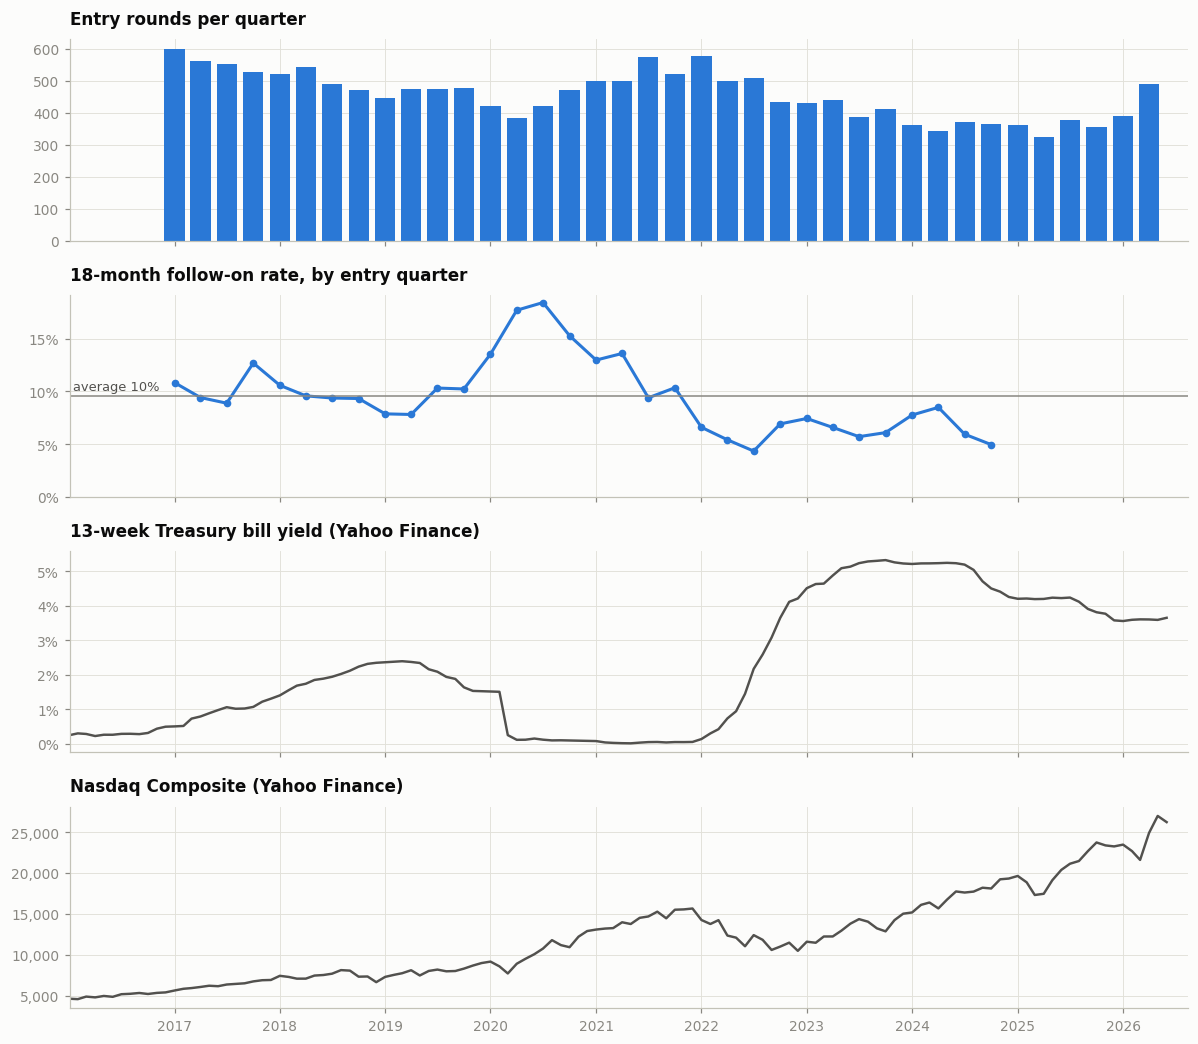

Follow-on rate for companies entering when short rates < 1%: 11.4% (n=5,778); >= 3%: 6.6% (n=3,557).


In [ ]:
def fetch_fred(series_id, start, attempts=3):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}&cosd={start:%Y-%m-%d}"
    for attempt in range(1, attempts + 1):
        try:
            resp = requests.get(url, timeout=60, headers={"User-Agent": "Mozilla/5.0"})
            resp.raise_for_status()
            df = pd.read_csv(io.StringIO(resp.text))
            values = pd.to_numeric(df.iloc[:, 1], errors="coerce")  # FRED marks missing days with "."
            series = pd.Series(values.to_numpy(), index=pd.to_datetime(df.iloc[:, 0], errors="coerce"), name=series_id)
            return series[series.index.notna()].dropna().sort_index().loc[start:]
        except (requests.RequestException, ValueError, IndexError) as exc:
            if attempt == attempts:
                print(f"FRED {series_id} unavailable after {attempts} attempts ({type(exc).__name__}).")
            else:
                time.sleep(3 * attempt)  # FRED occasionally times out from Colab; back off and retry
    return pd.Series(dtype=float, name=series_id)


def fetch_yahoo_close(ticker, start):
    try:
        hist = yf.Ticker(ticker).history(start=f"{start:%Y-%m-%d}", auto_adjust=True)
        if hist.empty or "Close" not in hist:
            raise ValueError("empty response")
        close = hist["Close"].dropna()
        close.index = pd.DatetimeIndex(close.index)
        if close.index.tz is not None:
            close.index = close.index.tz_convert(None)
        return close.rename(ticker)
    except Exception as exc:  # yfinance raises a wide range of errors when Yahoo changes its API
        print(f"Yahoo Finance {ticker} unavailable ({type(exc).__name__}).")
        return pd.Series(dtype=float, name=ticker)


macro_start = data_start - pd.DateOffset(years=1)
fed_funds = fetch_fred("FEDFUNDS", macro_start)
rate_label = "Effective Fed funds rate (FRED)"
if fed_funds.empty:
    fed_funds = fetch_yahoo_close("^IRX", macro_start)  # 13-week T-bill yield tracks the Fed funds rate closely
    rate_label = "13-week Treasury bill yield (Yahoo Finance)"
nasdaq = fetch_yahoo_close("^IXIC", macro_start)
if nasdaq.empty:
    nasdaq = fetch_fred("NASDAQCOM", macro_start)


def monthly(series, how):
    if series.empty:
        return pd.Series(dtype=float, index=pd.PeriodIndex([], freq="M"))
    return series.groupby(series.index.to_period("M")).agg(how)


macro = pd.DataFrame({"fed_funds": monthly(fed_funds, "mean"), "nasdaq": monthly(nasdaq, "last")})
macro = macro.reindex(pd.period_range(macro_start, data_end, freq="M"))
macro["nasdaq_6m_return"] = macro["nasdaq"] / macro["nasdaq"].shift(6) - 1

prev_month = entries["entry_date"].dt.to_period("M") - 1
entries["fed_funds"] = prev_month.map(macro["fed_funds"]).astype(float)
entries["nasdaq_6m_return"] = prev_month.map(macro["nasdaq_6m_return"]).astype(float)
print(f"Macro coverage: short-term rate on {entries['fed_funds'].notna().mean():.0%} of entries, "
      f"Nasdaq on {entries['nasdaq_6m_return'].notna().mean():.0%}.")

# Quarterly view: deal flow, follow-on rate and the rate/market backdrop
entries["cohort_q"] = entries["entry_date"].dt.to_period("Q")
q_all = entries.groupby("cohort_q").size()
q_lab = entries[entries["labeled"]].groupby("cohort_q")["follow_on"].agg(["mean", "size"])
q_lab = q_lab[q_lab["size"] >= 30]
x_all, x_lab = q_all.index.to_timestamp(), q_lab.index.to_timestamp()

panels = [("Entry rounds per quarter", None)]
panels.append(("18-month follow-on rate, by entry quarter", None))
if macro["fed_funds"].notna().any():
    panels.append((rate_label, "fed"))
if macro["nasdaq"].notna().any():
    panels.append(("Nasdaq Composite (Yahoo Finance)", "ndq"))

fig, axes = plt.subplots(len(panels), 1, figsize=(11, 2.3 * len(panels) + 0.4), sharex=True)
axes[0].bar(x_all, q_all.values, width=70, color=BLUE)
axes[0].set_title(panels[0][0])
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[1].plot(x_lab, q_lab["mean"].values, color=BLUE, marker="o", markersize=4)
if len(x_lab):
    axes[1].axhline(labeled["follow_on"].mean(), color=MUTED, linewidth=1)
    axes[1].annotate(f"average {labeled['follow_on'].mean():.0%}", (data_start, labeled["follow_on"].mean()),
                     xytext=(2, 4), textcoords="offset points", color=INK_2, fontsize=8.5)
axes[1].set_title(panels[1][0])
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
axes[1].set_ylim(bottom=0)
macro_x = macro.index.to_timestamp()
for ax, (title, key) in zip(axes[2:], panels[2:]):
    col = "fed_funds" if key == "fed" else "nasdaq"
    ax.plot(macro_x, macro[col].values, color=INK_2, linewidth=1.6)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(100, decimals=0) if key == "fed" else mtick.StrMethodFormatter("{x:,.0f}"))
axes[-1].set_xlim(data_start, data_end + pd.Timedelta(days=45))
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
plt.show()

if entries["fed_funds"].notna().any():
    lab_macro = entries[entries["labeled"] & entries["fed_funds"].notna()]
    low, high = lab_macro[lab_macro["fed_funds"] < 1], lab_macro[lab_macro["fed_funds"] >= 3]
    if len(low) and len(high):
        print(f"Follow-on rate for companies entering when short rates < 1%: {low['follow_on'].mean():.1%} (n={len(low):,}); "
              f">= 3%: {high['follow_on'].mean():.1%} (n={len(high):,}).")

## 8. Board and founder network
Form D doesn't name the investors in a round, but it does name the startup's officers and directors, and **VC funds file their own Form Ds that name their managers**. Matching names across the two gives a point-in-time view of who stands behind each company:
- **Fund manager on the board:** a director of the startup who appears as a related person on a venture-capital or private-equity fund's Form D filed *before* the entry round. That's usually the partner who led the round and took a board seat.
- **Repeat founder:** an officer who was already listed on another venture company's Form D before this one.
- **Board experience:** the most other startups any director had already sat on.

Names are matched on a normalized "first last" key. A name that had already appeared on more than 60 venture companies by the entry date is ignored for that entry, because it would link unrelated people. Every check uses only filings dated before the entry, so there's no look-ahead. Matches still carry some noise, which is covered in the limitations.

In [ ]:
fund_filing = (is_fund & as_text(filings["fund_type"]).isin(VC_FUND_TYPES)).fillna(False).astype(bool)
venture_filing = pd.Series(filings.index.isin(in_universe.index), index=filings.index)  # judged on the filing itself
meta = pd.DataFrame({"ACCESSIONNUMBER": filings["accession"].astype(str).to_numpy(), "cik": filings["cik"].to_numpy(),
                     "filing_date": filings["filing_date"].to_numpy(), "vc_fund": fund_filing.to_numpy(),
                     "venture": venture_filing.to_numpy()})
people_named = people_rows.dropna(subset=["person"]).assign(ACCESSIONNUMBER=lambda d: d["ACCESSIONNUMBER"].astype(str))
appearances = people_named.merge(meta, on="ACCESSIONNUMBER", how="inner")

fund_manager_since = appearances[appearances["vc_fund"]].groupby("person")["filing_date"].min()
first_seen_at = (appearances[appearances["venture"]]
                 .groupby(["person", "cik"], as_index=False)["filing_date"].min()
                 .rename(columns={"cik": "other_cik", "filing_date": "other_first_date"}))

# The people on each entry filing, and what they had done before the entry date
entry_keys = entries[["accession", "entry_date"]].assign(ACCESSIONNUMBER=lambda d: d["accession"].astype(str))
entry_people = appearances.merge(entry_keys[["ACCESSIONNUMBER", "entry_date"]], on="ACCESSIONNUMBER")
entry_people["fund_manager"] = (entry_people["person"].map(fund_manager_since) < entry_people["entry_date"]).fillna(False)
prior = entry_people[["ACCESSIONNUMBER", "person", "cik", "entry_date"]].merge(first_seen_at, on="person")
prior = prior[prior["other_cik"].ne(prior["cik"]) & (prior["other_first_date"] < prior["entry_date"])]
prior_counts = prior.groupby(["ACCESSIONNUMBER", "person"])["other_cik"].nunique().rename("prior_ventures").reset_index()
entry_people = entry_people.merge(prior_counts, on=["ACCESSIONNUMBER", "person"], how="left")
entry_people["prior_ventures"] = entry_people["prior_ventures"].fillna(0)

# A name already on too many startups by the entry date is too common to match reliably: ignore it for that entry.
# Judging this as of each entry date (not over the whole sample) keeps the filter free of look-ahead.
ambiguous = entry_people["prior_ventures"] > MAX_COMPANIES_PER_NAME
entry_people.loc[ambiguous, "fund_manager"] = False
entry_people.loc[ambiguous, "prior_ventures"] = 0
entry_people = entry_people.assign(
    fund_manager_director=entry_people["fund_manager"].astype(bool) & entry_people["is_director"].astype(bool),
    repeat_founder=entry_people["is_officer"].astype(bool) & entry_people["prior_ventures"].gt(0),
    director_prior=entry_people["prior_ventures"].where(entry_people["is_director"].astype(bool), 0),
)
network = entry_people.groupby("ACCESSIONNUMBER").agg(
    fund_managers_on_board=("fund_manager_director", "sum"),
    fund_managers_listed=("fund_manager", "sum"),
    repeat_founders=("repeat_founder", "sum"),
    board_experience=("director_prior", "max"),
)
for col in network.columns:
    entries[col] = entries["accession"].astype(str).map(network[col]).fillna(0).astype(float)

print(f"{appearances['person'].nunique():,} people matched across filings ({ambiguous.sum():,} person-entry matches ignored as too common); "
      f"{fund_manager_since.size:,} of them are listed on a VC or PE fund's Form D.")
lab_net = entries[entries["labeled"]]
signals = {
    "Fund manager on the board": lab_net["fund_managers_on_board"] > 0,
    "Repeat founder among officers": lab_net["repeat_founders"] > 0,
    "Director with prior startup boards": lab_net["board_experience"] > 0,
}
display(pd.DataFrame([
    {"Signal": name, "Share of entry rounds": flag.mean(),
     "Follow-on rate with": lab_net.loc[flag, "follow_on"].mean(),
     "Follow-on rate without": lab_net.loc[~flag, "follow_on"].mean()}
    for name, flag in signals.items()
]).style.format({"Share of entry rounds": "{:.1%}", "Follow-on rate with": "{:.1%}",
                 "Follow-on rate without": "{:.1%}"}, na_rep="-").hide(axis="index"))

307,856 people matched across filings (32 person-entry matches ignored as too common); 35,245 of them are listed on a VC or PE fund's Form D.


Signal,Share of entry rounds,Follow-on rate with,Follow-on rate without
Fund manager on the board,14.6%,11.9%,9.1%
Repeat founder among officers,22.7%,10.5%,9.3%
Director with prior startup boards,36.9%,10.7%,8.9%


## 9. Point-in-time features
Every feature comes from the entry notice itself or from filings dated before it. Nothing is taken from later amendments. The features encode what an experienced seed investor reads between the lines of a filing:

| Signal | Why it matters |
|---|---|
| Fund manager on the board, repeat founders, board experience | Who backs the company and who runs it, the classic VC pattern-matching signals |
| Round size, target size, fill ratio | Larger, fully subscribed rounds suggest institutional demand |
| Investor count and average check | A few large checks points to funds; many small checks points to friends-and-family or crowdfunding |
| Directors and officers listed | Board seats often come with an institutional lead |
| Brokers, finders fees, 506(c), non-accredited investors | Paid placement and general solicitation are uncommon in institutional venture rounds |
| Delaware C-corp, hub state, sector | The standard VC-backable structure and ecosystem |
| Security type (equity, SAFE/option, debt) | The instrument hints at the round type |
| Filing lag (first sale to filing) | Companies with experienced counsel tend to file on time |
| Name keywords (AI, Labs, Bio) | A light alternative-data signal from the name |

29 numeric + 3 categorical features for 17,366 entry rounds.


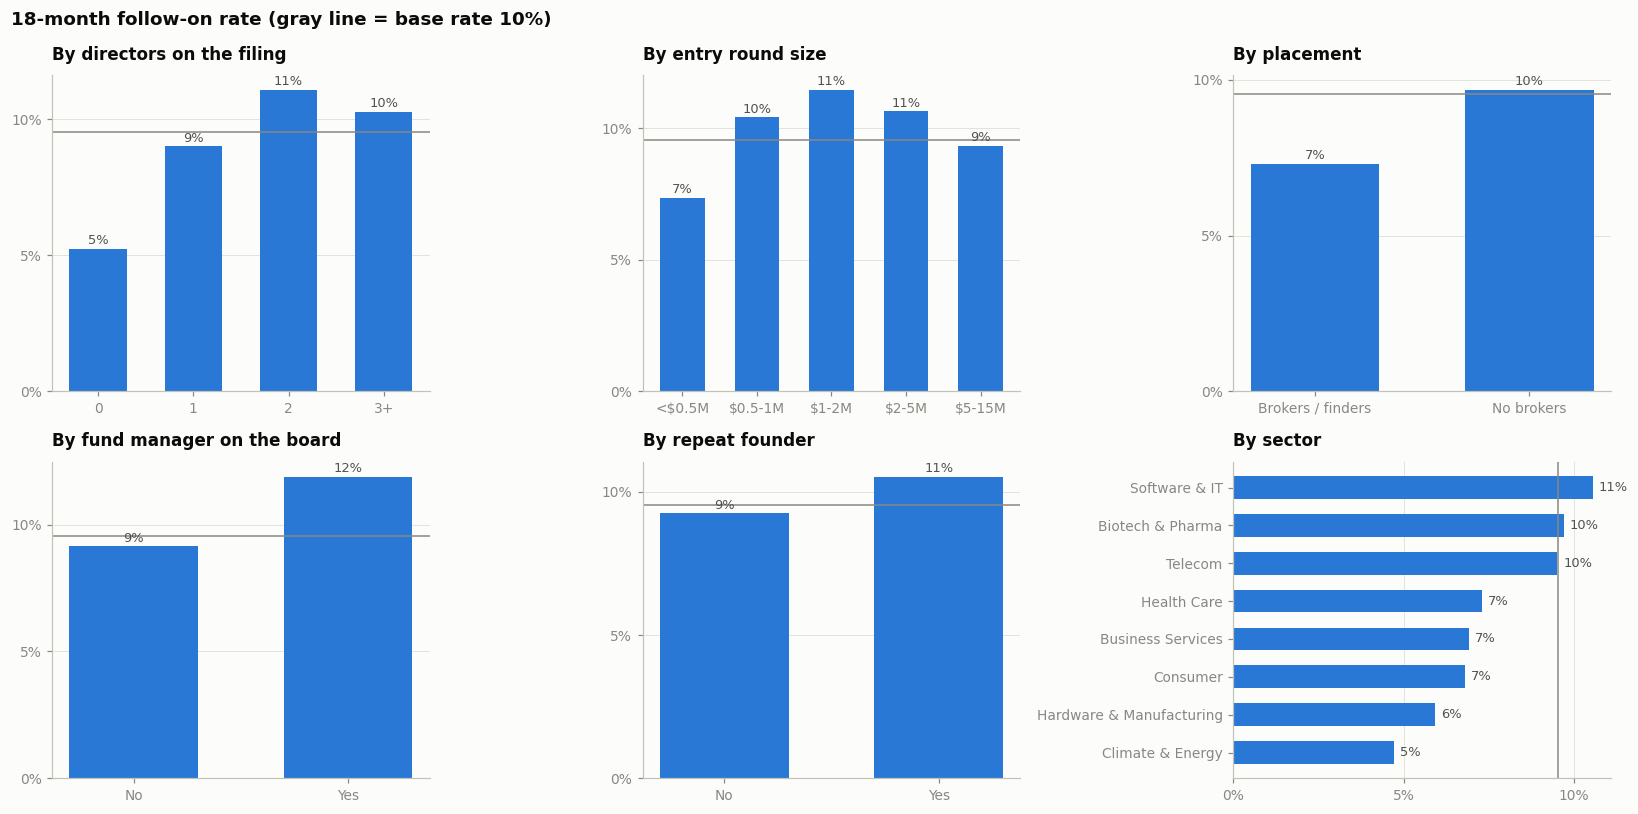

In [ ]:
CATEGORICAL_FEATURES = ["sector", "hub", "revenue_band"]
FEATURE_LABELS = {
    "log_round_size": "Round size", "log_target_size": "Target size", "fill_ratio": "Share of target sold",
    "target_indefinite": "Open-ended target", "log_investors": "Number of investors", "log_avg_check": "Average check size",
    "log_min_investment": "Minimum investment", "n_directors": "Directors listed", "n_officers": "Officers listed",
    "n_related_persons": "People listed", "uses_brokers": "Brokers or finders paid", "company_age": "Company age",
    "filing_lag_days": "Days from first sale to filing", "is_equity": "Equity security", "is_debt": "Debt / convertible note",
    "is_option": "Option or SAFE-like security", "is_other_security": "Other security type",
    "has_nonaccredited": "Non-accredited investors", "is_506c": "Rule 506(c) general solicitation",
    "multi_year_offering": "Offering open over 1 year", "delaware": "Delaware incorporation",
    "corporation": "Corporation (vs LLC)", "name_ai": "'AI' in name", "name_labs": "'Labs' in name",
    "name_bio": "Bio / pharma name", "fund_managers_on_board": "Fund manager on the board",
    "fund_managers_listed": "Fund managers listed (any role)", "repeat_founders": "Repeat founders",
    "log_board_experience": "Board experience (prior startups)",
    "sector": "Sector", "hub": "Location hub", "revenue_band": "Revenue band",
}


def revenue_band(text):
    t = as_text(text).str.lower().fillna("")
    conditions = [t.str.contains("no revenue", regex=False), t.str.contains("decline", regex=False),
                  t.str.match(r"^\$?1\s*-"), t.str.contains("1,000,001", regex=False),
                  t.str.contains(r"5,000,001|25,000,001|over \$100", regex=True)]
    bands = np.select(
        [c.fillna(False).to_numpy(dtype=bool) for c in conditions],
        ["No revenue", "Declined to disclose", "Under $1M", "$1M-$5M", "Over $5M"], default="Unknown")
    return pd.Series(bands, index=text.index)


def build_features(df):
    sold, offered, investors = df["amount_sold"], df["amount_offered"], df["n_investors"]
    state = as_text(df["state"])
    X = pd.DataFrame(index=df.index)
    X["log_round_size"] = np.log10(sold.clip(lower=1))
    X["log_target_size"] = np.log10(offered.where(offered > 0))
    X["fill_ratio"] = (sold / offered.where(offered > 0)).clip(0, 2)
    X["target_indefinite"] = df["offering_indefinite"].astype(int)
    X["log_investors"] = np.log1p(investors)
    X["log_avg_check"] = np.log10((sold / investors.where(investors > 0)).clip(lower=1))
    X["log_min_investment"] = np.log10(df["min_investment"].clip(lower=1))
    X["n_directors"] = df["n_directors"]
    X["n_officers"] = df["n_officers"]
    X["n_related_persons"] = df["n_related_persons"]
    X["uses_brokers"] = ((df["n_recipients"] > 0) | (df["sales_comm"].fillna(0) + df["finders_fee"].fillna(0) > 0)).astype(int)
    X["company_age"] = (df["entry_date"].dt.year - df["year_inc"]).clip(-1, 10)
    X["filing_lag_days"] = (df["entry_date"] - df["sale_date"]).dt.days.clip(-30, 730)
    for col in ["is_equity", "is_debt", "is_option", "is_other_security", "has_nonaccredited", "is_506c", "multi_year_offering"]:
        X[col] = df[col].astype(int)
    X["delaware"] = contains(df["jurisdiction"], "DELAWARE", case=True).astype(int)
    X["corporation"] = df["entity_type"].eq("corporation").fillna(False).astype(int)
    X["name_ai"] = contains(df["company"], r"\bAI\b|\.AI\b|ARTIFICIAL INTELLIGENCE").astype(int)
    X["name_labs"] = contains(df["company"], r"\bLABS?\b").astype(int)
    X["name_bio"] = contains(df["company"], r"\bBIO|THERAPEUTIC|PHARMA").astype(int)
    X["fund_managers_on_board"] = df["fund_managers_on_board"].clip(0, 3)
    X["fund_managers_listed"] = df["fund_managers_listed"].clip(0, 5)
    X["repeat_founders"] = df["repeat_founders"].clip(0, 3)
    X["log_board_experience"] = np.log1p(df["board_experience"].clip(0, 50))
    X["sector"] = df["sector"].astype(object)
    X["hub"] = np.where(state.isin(TECH_HUBS).fillna(False), state.astype(object),
                        np.where(state.isin(US_STATES).fillna(False), "Other US", "Non-US"))
    X["revenue_band"] = revenue_band(df["revenue_range"])
    for col in CATEGORICAL_FEATURES:
        X[col] = X[col].astype(object).where(X[col].notna(), "Unknown")
    return X


X_all = build_features(entries)
NUMERIC_FEATURES = [c for c in X_all.columns if c not in CATEGORICAL_FEATURES and X_all[c].notna().any()]
y_all = entries["follow_on"]
lab_idx = entries.index[entries["labeled"]]
print(f"{len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical features for {len(X_all):,} entry rounds.")

# What partners intuit, checked against the data (labeled entries only)
view = X_all.loc[lab_idx].assign(follow_on=y_all.loc[lab_idx])
base_rate = view["follow_on"].mean()
views = {
    "By directors on the filing": pd.cut(view["n_directors"], [-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"]),
    "By entry round size": pd.cut(view["log_round_size"], np.log10([1e5, 5e5, 1e6, 2e6, 5e6, 1.5e7 + 1]),
                                  labels=["<$0.5M", "$0.5-1M", "$1-2M", "$2-5M", "$5-15M"], include_lowest=True),
    "By placement": view["uses_brokers"].map({0: "No brokers", 1: "Brokers / finders"}),
    "By fund manager on the board": np.where(view["fund_managers_on_board"] > 0, "Yes", "No"),
    "By repeat founder": np.where(view["repeat_founders"] > 0, "Yes", "No"),
    "By sector": view["sector"],
}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (title, groups) in zip(axes.flat, views.items()):
    groups = pd.Series(groups, index=view.index)
    rate = view.groupby(groups, observed=True)["follow_on"].agg(["mean", "size"])
    rate = rate[rate["size"] >= 20]
    horizontal = title == "By sector"
    if horizontal:
        rate = rate.sort_values("mean")
        ax.barh(rate.index.astype(str), rate["mean"], color=BLUE, height=0.6)
        ax.axvline(base_rate, color=MUTED, linewidth=1)
        ax.xaxis.set_major_locator(mtick.MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
        for i, v in enumerate(rate["mean"]):
            ax.annotate(f"{v:.0%}", (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5, color=INK_2)
        ax.grid(axis="y", visible=False)
    else:
        ax.bar(rate.index.astype(str), rate["mean"], color=BLUE, width=0.6)
        ax.axhline(base_rate, color=MUTED, linewidth=1)
        ax.yaxis.set_major_locator(mtick.MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
        for i, v in enumerate(rate["mean"]):
            ax.annotate(f"{v:.0%}", (i, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5, color=INK_2)
        ax.grid(axis="x", visible=False)
    ax.set_title(title)
fig.suptitle(f"18-month follow-on rate (gray line = base rate {base_rate:.0%})", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

## 10. Walk-forward validation with an embargo
Each fold tests on one calendar year of entry rounds. The training set only includes rounds whose **18-month outcome was already known before that year began**. A random split, or even a plain time split, would train on labels that resolve inside the test period, a subtle leak that inflates results.

Three contenders:
- **Heuristic rule:** a transparent checklist a junior analyst might use (Delaware incorporation, corporation, based in CA/NY/MA, round of $1M or more, a director on file, no brokers).
- **Logistic regression:** standardized features plus one-hot sectors.
- **Gradient boosting:** scikit-learn's `HistGradientBoostingClassifier`, which handles missing values natively.

**Choosing without cheating.** The test years are split in two. The model with the higher PR AUC on the **earlier half** is selected, and the headline numbers come only from the **later half**, which played no part in the choice. Reporting the winner on the same years used to pick it would flatter it slightly.

**Main metric:** the hit rate in the **top 100 per year**, meaning how many of the companies a partner would actually review went on to raise a larger round. We also report the lift over the base rate, ROC AUC and PR AUC.

In [ ]:
def make_logistic():
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATEGORICAL_FEATURES),
    ])
    return Pipeline([("prep", prep), ("model", LogisticRegression(C=0.3, max_iter=3000))])


def make_boosting():
    prep = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                               encoded_missing_value=np.nan), CATEGORICAL_FEATURES),
        ("num", "passthrough", NUMERIC_FEATURES),
    ])
    model = HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=40, l2_regularization=1.0,
        early_stopping=False,  # sklearn's default turns this on only above 10,000 rows, which would vary by fold
        categorical_features=list(range(len(CATEGORICAL_FEATURES))), random_state=RANDOM_STATE)
    return Pipeline([("prep", prep), ("model", model)])


def heuristic_score(X):
    checklist = (X["delaware"] + X["corporation"] + X["hub"].isin(HEURISTIC_HUBS).astype(int)
                 + (X["log_round_size"] >= 6).astype(int) + (X["n_directors"] >= 1).astype(int)
                 + (1 - X["uses_brokers"]))
    return (checklist + 0.01 * X["log_round_size"].fillna(0)).to_numpy()  # bigger round breaks ties


def hit_rate_at_k(y, score, k):
    top = np.argsort(-score, kind="stable")[:k]
    return float(np.asarray(y)[top].mean())


MODELS = {"Heuristic rule": None, "Logistic regression": make_logistic, "Gradient boosting": make_boosting}
lab = entries.loc[lab_idx]
fold_rows, oos_parts = [], []
last_fold = {}
for test_year in sorted(lab["cohort_year"].unique()):
    train_mask = lab["entry_date"] + window < pd.Timestamp(year=test_year, month=1, day=1)
    test_mask = lab["cohort_year"].eq(test_year)
    y_train = y_all.loc[lab.index[train_mask.to_numpy()]]
    y_test = y_all.loc[lab.index[test_mask.to_numpy()]]
    if len(y_train) < MIN_TRAIN_ROWS or y_train.sum() < 30 or len(y_test) < 200 or y_test.nunique() < 2:
        continue
    X_train, X_test = X_all.loc[y_train.index], X_all.loc[y_test.index]
    k = min(TOP_K, len(y_test))
    for name, factory in MODELS.items():
        if factory is None:
            score = heuristic_score(X_test)
        else:
            model = factory().fit(X_train, y_train)
            score = model.predict_proba(X_test)[:, 1]
            last_fold[name] = {"model": model, "X": X_test, "y": y_test, "year": test_year}
        fold_rows.append({
            "test_year": test_year, "model": name, "train_rows": len(y_train), "test_rows": len(y_test),
            "base_rate": y_test.mean(), f"hit_rate_top{TOP_K}": hit_rate_at_k(y_test, score, k),
            "roc_auc": roc_auc_score(y_test, score), "pr_auc": average_precision_score(y_test, score),
        })
        oos_parts.append(pd.DataFrame({"idx": y_test.index, "test_year": test_year, "model": name,
                                       "y": y_test.to_numpy(), "score": score}))

if not fold_rows:
    raise RuntimeError("Not enough labeled history for walk-forward validation; lower START_YEAR.")

folds = pd.DataFrame(fold_rows)
folds[f"lift_top{TOP_K}"] = folds[f"hit_rate_top{TOP_K}"] / folds["base_rate"]
oos = pd.concat(oos_parts, ignore_index=True)
hit_col, lift_col = f"hit_rate_top{TOP_K}", f"lift_top{TOP_K}"

METRICS = ["base_rate", hit_col, lift_col, "roc_auc", "pr_auc"]
fmt = {"base_rate": "{:.1%}", hit_col: "{:.1%}", lift_col: "{:.2f}x", "roc_auc": "{:.3f}", "pr_auc": "{:.3f}"}
summary = folds.groupby("model")[METRICS].mean().reindex(list(MODELS))
print(f"All test years ({folds['test_year'].min()} to {folds['test_year'].max()}), averaged:")
display(summary.style.format(fmt))

# Choose the model on the earlier test years, then report it only on the later years it never influenced
test_years = sorted(folds["test_year"].unique())
n_select = max(1, len(test_years) // 2)
SELECT_YEARS = test_years[:n_select]
REPORT_YEARS = test_years[n_select:] or SELECT_YEARS
selection = folds[folds["test_year"].isin(SELECT_YEARS)].groupby("model")["pr_auc"].mean()
BEST_MODEL = selection.loc[["Logistic regression", "Gradient boosting"]].idxmax()
headline = folds[folds["test_year"].isin(REPORT_YEARS)].groupby("model")[METRICS].mean().reindex(list(MODELS))
print(f"Model chosen on {SELECT_YEARS[0]}-{SELECT_YEARS[-1]} (higher average PR AUC): {BEST_MODEL}.")
print(f"Headline results on the untouched years {REPORT_YEARS[0]}-{REPORT_YEARS[-1]}:")
display(headline.style.format(fmt))
print(f"{BEST_MODEL} by test year:")
display(folds[folds["model"].eq(BEST_MODEL)]
        .drop(columns="model").set_index("test_year")
        .style.format({**fmt, "train_rows": "{:,}", "test_rows": "{:,}"}))

All test years (2019 to 2024), averaged:


,base_rate,hit_rate_top100,lift_top100,roc_auc,pr_auc
model,,,,,
Heuristic rule,9.3%,11.7%,1.17x,0.585,0.118
Logistic regression,9.3%,17.8%,2.01x,0.633,0.145
Gradient boosting,9.3%,18.2%,1.99x,0.627,0.146


Model chosen on 2019-2021 (higher average PR AUC): Gradient boosting.
Headline results on the untouched years 2022-2024:


,base_rate,hit_rate_top100,lift_top100,roc_auc,pr_auc
model,,,,,
Heuristic rule,6.3%,7.0%,1.08x,0.566,0.074
Logistic regression,6.3%,15.0%,2.40x,0.628,0.112
Gradient boosting,6.3%,13.0%,2.06x,0.633,0.107


Gradient boosting by test year:


,train_rows,test_rows,base_rate,hit_rate_top100,roc_auc,pr_auc,lift_top100
test_year,,,,,,,
2019,"1,199","1,873",9.1%,21.0%,0.616,0.148,2.31x
2020,"3,346","1,699",16.2%,32.0%,0.635,0.252,1.98x
2021,"5,232","2,098",11.5%,17.0%,0.615,0.154,1.48x
2022,"6,982","2,019",5.8%,13.0%,0.617,0.105,2.24x
2023,"8,893","1,669",6.5%,14.0%,0.651,0.110,2.16x
2024,"11,040","1,438",6.7%,12.0%,0.630,0.106,1.78x


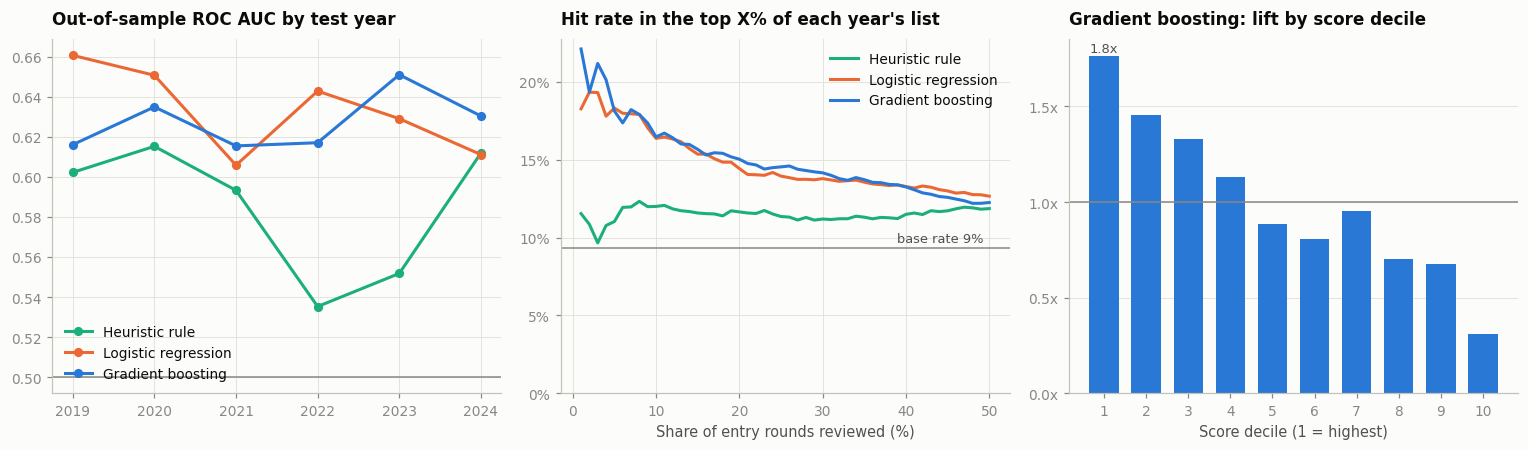

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

# (a) ROC AUC by test year
ax = axes[0]
for name in MODELS:
    f = folds[folds["model"].eq(name)]
    ax.plot(f["test_year"], f["roc_auc"], color=MODEL_COLORS[name], marker="o", markersize=5, label=name)
ax.axhline(0.5, color=MUTED, linewidth=1)
ax.set_title("Out-of-sample ROC AUC by test year")
ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True))
ax.legend(loc="lower left")

# (b) Hit rate when a partner reviews the top X% of each year's list
ax = axes[1]
shares = np.linspace(0.01, 0.5, 50)
oos["pct_rank"] = oos.groupby(["model", "test_year"])["score"].rank(ascending=False, pct=True, method="first")
for name in MODELS:
    o = oos[oos["model"].eq(name)]
    ax.plot(shares * 100, [o.loc[o["pct_rank"] <= s, "y"].mean() for s in shares], color=MODEL_COLORS[name], label=name)
overall = oos[oos["model"].eq(BEST_MODEL)]["y"].mean()
ax.axhline(overall, color=MUTED, linewidth=1)
ax.annotate(f"base rate {overall:.0%}", (50, overall), xytext=(-4, 4), textcoords="offset points", ha="right", fontsize=8.5, color=INK_2)
ax.set_title("Hit rate in the top X% of each year's list")
ax.set_xlabel("Share of entry rounds reviewed (%)")
ax.yaxis.set_major_locator(mtick.MaxNLocator(nbins=6, steps=[1, 2, 5, 10]))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(bottom=0)
ax.legend(loc="upper right")

# (c) Lift by score decile for the main model
ax = axes[2]
g = oos[oos["model"].eq(BEST_MODEL)].copy()
g["decile"] = np.ceil(g["pct_rank"] * 10).clip(1, 10).astype(int)
lift = g.groupby("decile")["y"].mean() / g["y"].mean()
ax.bar(lift.index, lift.values, color=MODEL_COLORS[BEST_MODEL], width=0.7)
ax.axhline(1, color=MUTED, linewidth=1)
ax.annotate(f"{lift.iloc[0]:.1f}x", (lift.index[0], lift.iloc[0]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5, color=INK_2)
ax.set_title(f"{BEST_MODEL}: lift by score decile")
ax.set_xlabel("Score decile (1 = highest)")
ax.set_xticks(range(1, 11))
ax.yaxis.set_major_locator(mtick.MaxNLocator(nbins=6, steps=[1, 2, 5, 10]))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:.1f}x"))
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## 11. What drives the score
Permutation importance for the selected model on the most recent test year measures how much the ranking quality (PR AUC) drops when each feature is shuffled. It shows what the model relies on out of sample, which is more honest than in-sample split counts.

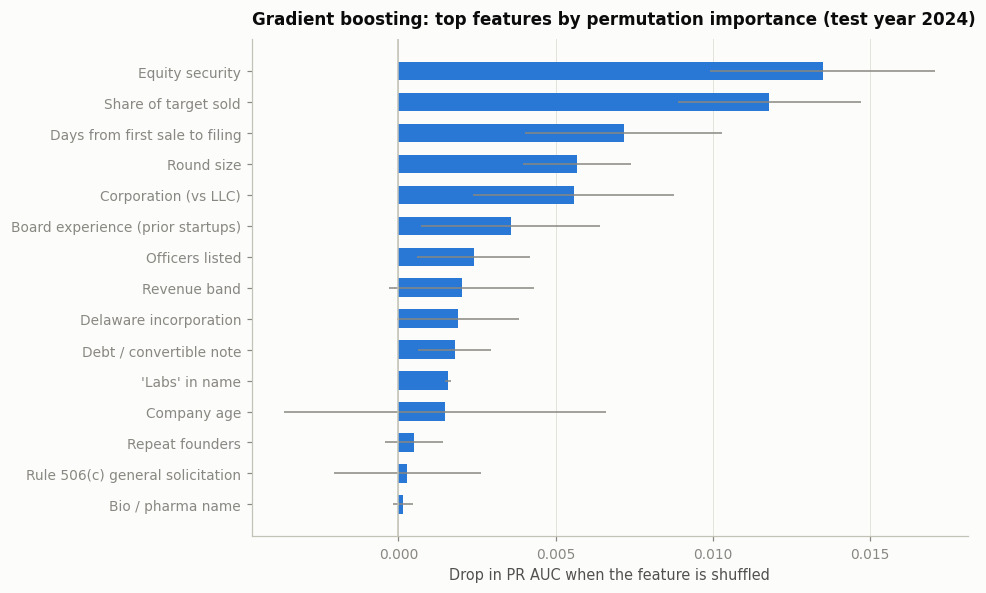

In [ ]:
fold = last_fold[BEST_MODEL]
imp = permutation_importance(fold["model"], fold["X"], fold["y"], scoring="average_precision",
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"feature": fold["X"].columns, "mean": imp.importances_mean, "std": imp.importances_std})
                .sort_values("mean", ascending=False).head(15).iloc[::-1])
importance["label"] = importance["feature"].map(FEATURE_LABELS).fillna(importance["feature"])
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importance["label"], importance["mean"], xerr=importance["std"], color=MODEL_COLORS[BEST_MODEL], height=0.6,
        error_kw={"ecolor": MUTED, "elinewidth": 1, "capsize": 0})
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_title(f"{BEST_MODEL}: top features by permutation importance (test year {fold['year']})")
ax.set_xlabel("Drop in PR AUC when the feature is shuffled")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 12. Live watchlist
The selected model is retrained on every labeled entry round and scores companies whose 18-month window is still open, meaning young companies that raised recently.

The raw model score ranks companies well, but it reflects the average success rate of all training years, which is higher than today's. So the scores are **recalibrated**: a single shift in log-odds makes the average estimate on the most recent fully labeled year equal that year's actual base rate. The ranking doesn't change; the probabilities become realistic for current conditions. The table shows the top of the list, with a flag for companies that have already filed a larger round since. The model never trained on these companies, so the flag is an early out-of-sample check. The full list is saved as a CSV.

In [ ]:
final_model = MODELS[BEST_MODEL]().fit(X_all.loc[lab_idx], y_all.loc[lab_idx])
live = entries[~entries["labeled"]].copy()
if live.empty:
    print("No open entry rounds: the data ends more than 18 months after the last entry.")
else:
    # The raw score ranks well but reflects the average base rate of all training years. Shift it (in log-odds)
    # so the average estimate on the most recent fully labeled year matches that year's actual base rate.
    def logit(p):
        p = np.clip(p, 1e-6, 1 - 1e-6)
        return np.log(p / (1 - p))

    def sigmoid(z):
        return 1 / (1 + np.exp(-z))

    recent_year = max(REPORT_YEARS)
    recent_idx = entries.index[entries["labeled"] & entries["cohort_year"].eq(recent_year)]
    recent_logit = logit(final_model.predict_proba(X_all.loc[recent_idx])[:, 1])
    recent_rate = y_all.loc[recent_idx].mean()
    lo, hi = -10.0, 10.0
    for _ in range(60):  # bisection for the log-odds shift
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if sigmoid(recent_logit + mid).mean() < recent_rate else (lo, mid)
    logit_shift = (lo + hi) / 2

    live["score"] = final_model.predict_proba(X_all.loc[live.index])[:, 1]
    live["probability"] = sigmoid(logit(live["score"].to_numpy()) + logit_shift)
    live["percentile"] = live["score"].rank(pct=True) * 100
    print(f"Probabilities recalibrated to {recent_year} conditions (base rate {recent_rate:.1%}); "
          f"average estimate across the live list: {live['probability'].mean():.1%}.")
    live["months_since_entry"] = ((data_end - live["entry_date"]).dt.days / 30.4).round(0).astype(int)
    live = live.sort_values("score", ascending=False)
    live["shortlist"] = np.where(np.arange(len(live)) < TOP_K, f"Top {TOP_K}", "Rest")

    watch = pd.DataFrame({
        "Company": live["company"],
        "Location": live["city"].fillna("") + ", " + live["state"].fillna(""),
        "Sector": live["sector"],
        "Entry filing": live["entry_date"].dt.strftime("%b %Y"),
        "Round": live["entry_round_size"].map(lambda v: f"${v / 1e6:,.1f}M"),
        "Investors": live["n_investors"].map(lambda v: "-" if pd.isna(v) else f"{v:.0f}"),
        "Directors": live["n_directors"].astype(int),
        "Fund manager on board": np.where(live["fund_managers_on_board"] > 0, "Yes", ""),
        "Repeat founders": live["repeat_founders"].astype(int),
        "Est. probability": live["probability"].map(lambda v: f"{v:.1%}"),
        "Percentile": live["percentile"].map(lambda v: f"{v:.1f}"),
        "Larger round filed since": np.where(live["follow_on"].eq(1), "Yes", ""),
    })
    print(f"Top 25 of {len(live):,} open entry rounds (data through {data_end:%d %b %Y}):")
    display(watch.head(25).reset_index(drop=True))

    matured = live[live["months_since_entry"] >= 9]
    if len(matured) >= 2 * TOP_K:
        top = matured.head(TOP_K)
        print(f"Early read: among open entries at least 9 months old, {top['follow_on'].mean():.1%} of the top {TOP_K} "
              f"have already filed a larger round vs {matured['follow_on'].mean():.1%} of all {len(matured):,}.")

    out_path = OUTPUT_DIR / "deal_sourcing_watchlist.csv"
    live.drop(columns=["shortlist"]).to_csv(out_path, index=False)
    print(f"Full scored list saved to {out_path}")

    plot_df = pd.DataFrame({
        "Company": live["company"].astype(object).fillna(""),
        "Fund manager on board": np.where(live["fund_managers_on_board"] > 0, "Yes", "No"),
        "Sector": live["sector"].astype(object).fillna("Unknown"),
        "State": live["state"].astype(object).fillna(""),
        "Investors": live["n_investors"].astype(float),
        "Directors": live["n_directors"].astype(float),
        "Round size": live["entry_round_size"].astype(float),
        "Probability": live["probability"].astype(float),
        "List": live["shortlist"].astype(object),
    })
    fig = px.scatter(
        plot_df, x="Round size", y="Probability", color="List", log_x=True, opacity=0.75,
        color_discrete_map={f"Top {TOP_K}": BLUE, "Rest": AXIS},
        category_orders={"List": [f"Top {TOP_K}", "Rest"]},
        hover_name="Company",
        hover_data={"Sector": True, "State": True, "Investors": ":.0f", "Directors": ":.0f", "Fund manager on board": True,
                    "Round size": ":$,.0f", "Probability": ":.1%", "List": False},
        labels={"Round size": "Entry round size (USD, log scale)",
                "Probability": f"Est. follow-on probability ({recent_year} conditions)", "List": ""},
        title="Live watchlist: open entry rounds scored by the model",
    )
    fig.update_traces(marker={"size": 7, "line": {"width": 1, "color": SURFACE}})
    fig.update_layout(template="plotly_white", height=480, yaxis_tickformat=".0%",
                      plot_bgcolor=SURFACE, paper_bgcolor=SURFACE, legend={"orientation": "h", "y": 1.08})
    fig.show()

Probabilities recalibrated to 2024 conditions (base rate 6.7%); average estimate across the live list: 6.5%.
Top 25 of 2,285 open entry rounds (data through 30 Jun 2026):


,Company,Location,Sector,Entry filing,Round,Investors,Directors,Fund manager on board,Repeat founders,Est. probability,Percentile,Larger round filed since
0,"Kaffea-X, Inc.","Randolph, NJ",Software & IT,Mar 2025,$1.9M,4,10,,0,40.9%,100.0,
1,Diskover Data Inc.,"Milpitas, CA",Software & IT,Sep 2025,$7.5M,4,5,Yes,1,31.8%,100.0,
2,"Capitan Orthopedics, Inc.","Grand Rapids, MI",Health Care,Jan 2026,$2.0M,2,4,,1,31.4%,99.9,
3,Pairidex Inc.,"St. Louis, MO",Biotech & Pharma,Feb 2025,$1.1M,16,3,Yes,0,29.7%,99.9,
4,"dynama, Inc.","Austin, TX",Software & IT,Jun 2026,$2.9M,3,3,,0,28.5%,99.8,
5,"Elastro, Inc.","Watertown, MA",Biotech & Pharma,Aug 2025,$2.3M,6,4,Yes,1,28.3%,99.8,
6,"Legata, Inc.","Mercer Island, WA",Software & IT,Aug 2025,$0.7M,10,3,,1,27.2%,99.7,
7,Zing Coach Inc.,"West Palm Beach, FL",Software & IT,Oct 2025,$2.4M,4,5,Yes,0,27.2%,99.7,
8,Mechanus Labs Inc.,"Dover, DE",Software & IT,May 2025,$7.4M,36,2,,1,27.1%,99.6,
9,Impresa Corp.,"Agoura Hills, CA",Software & IT,May 2025,$0.5M,10,3,,0,26.8%,99.6,


Early read: among open entries at least 9 months old, 7.0% of the top 100 have already filed a larger round vs 4.6% of all 1,107.
Full scored list saved to /content/deal_sourcing_watchlist.csv


## 13. Limitations
- **Coverage.** Not every seed round files a Form D. Some SAFE rounds and many angel checks never appear, so the universe skews toward priced rounds and companies with diligent counsel.
- **Label proxy.** A larger Form D is not the same as a priced Series A. Bridge rounds, re-filed offerings and companies that re-incorporate under a new CIK add noise in both directions.
- **Partial investor identity.** Form D doesn't name the fund that led a round. The fund-manager signal infers it by matching director names against fund filings, so namesakes can create false matches and partners who never appear on a fund's Form D are missed. Joining investor data from Crunchbase or PitchBook would be the biggest upgrade.
- **Short lookback for network features.** Board and founder history only goes back to the first year loaded, so the earliest cohorts look less connected than they really were.
- **Regime shifts.** The 2021 boom and the 2022 to 2023 reset move base rates by a wide margin. Walk-forward tests measure ranking within each year; the predicted probabilities are not calibrated across regimes.
- **Next steps.** Enrich companies with traction signals (GitHub activity, Hacker News launches, web traffic, hiring), check whether repeat founders' earlier companies succeeded, and backtest the watchlist against rounds announced in the press.

In [ ]:
gb = headline.loc[BEST_MODEL]
print("Key results")
print(f"  Filings processed:        {len(filings):,} ({loaded[0]} to {loaded[-1]})")
print(f"  Funding rounds rebuilt:   {len(rounds):,}")
print(f"  Labeled entry rounds:     {len(lab_idx):,} (base rate {labeled['follow_on'].mean():.1%})")
print(f"  Walk-forward test years:  {folds['test_year'].nunique()} ({folds['test_year'].min()} to {folds['test_year'].max()})")
print(f"  Selected model:           {BEST_MODEL} (chosen on {SELECT_YEARS[0]}-{SELECT_YEARS[-1]})")
print(f"  Headline years:           {REPORT_YEARS[0]}-{REPORT_YEARS[-1]} (never used for model choice)")
print(f"  Top-{TOP_K} hit rate:         {gb[hit_col]:.1%} vs {gb['base_rate']:.1%} base rate ({gb[lift_col]:.1f}x lift)")
print(f"  ROC AUC:                  {gb['roc_auc']:.3f} (heuristic rule {headline.loc['Heuristic rule', 'roc_auc']:.3f})")
print()
print("Resume bullet:")
print(f"- Built an early-stage deal-sourcing model in Python on {len(filings) / 1000:,.0f}k SEC Form D filings, "
      f"reconstructing {len(rounds) / 1000:,.0f}k funding rounds and matching startup boards to VC fund filings "
      f"to predict 18-month follow-on raises; "
      f"on held-out {REPORT_YEARS[0]}-{REPORT_YEARS[-1]} cohorts (embargoed walk-forward), the top-{TOP_K} yearly shortlist delivered a {gb[lift_col]:.1f}x lift "
      f"({gb[hit_col]:.0%} hit rate vs {gb['base_rate']:.0%} base rate, ROC AUC {gb['roc_auc']:.2f}).")

Key results
  Filings processed:        538,768 (2016Q1 to 2026Q2)
  Funding rounds rebuilt:   70,767
  Labeled entry rounds:     15,081 (base rate 9.5%)
  Walk-forward test years:  6 (2019 to 2024)
  Selected model:           Gradient boosting (chosen on 2019-2021)
  Headline years:           2022-2024 (never used for model choice)
  Top-100 hit rate:         13.0% vs 6.3% base rate (2.1x lift)
  ROC AUC:                  0.633 (heuristic rule 0.566)

Resume bullet:
- Built an early-stage deal-sourcing model in Python on 539k SEC Form D filings, reconstructing 71k funding rounds and matching startup boards to VC fund filings to predict 18-month follow-on raises; on held-out 2022-2024 cohorts (embargoed walk-forward), the top-100 yearly shortlist delivered a 2.1x lift (13% hit rate vs 6% base rate, ROC AUC 0.63).


## Summary
This notebook builds a seed-stage deal-sourcing engine from public data. It downloads every SEC Form D filing since 2016, filters out funds and non-venture issuers, rebuilds funding rounds by linking amendments to their original notices, and identifies each young company's first round. It then labels whether the company raised a round of at least $1M and 1.5x larger within 18 months, matches board members against VC fund filings to spot institutional backing and repeat founders, charts the funding climate from FRED and Yahoo Finance, and ranks companies with a logistic regression or gradient-boosting model, whichever wins an embargoed walk-forward test. The result is a live watchlist of recently funded companies, scored and exported to CSV.

**Resume-ready bullet** (the cell above fills in the numbers from your run):
- Built an early-stage deal-sourcing model in Python on [N]k SEC Form D filings, reconstructing [N]k funding rounds and matching startup boards to VC fund filings to predict 18-month follow-on raises; on held-out cohorts (embargoed walk-forward), the top-100 yearly shortlist delivered a [X]x lift ([Y]% hit rate vs [Z]% base rate).